
Model Comparison (Decision Tree vs Random Forest):
   Metric  Decision Tree  Random Forest
 Accuracy       0.948389       0.954689
Precision       0.838602       0.879159
   Recall       0.812903       0.809677
 F1-Score       0.825553       0.842989

Experiment 7 Completed Successfully


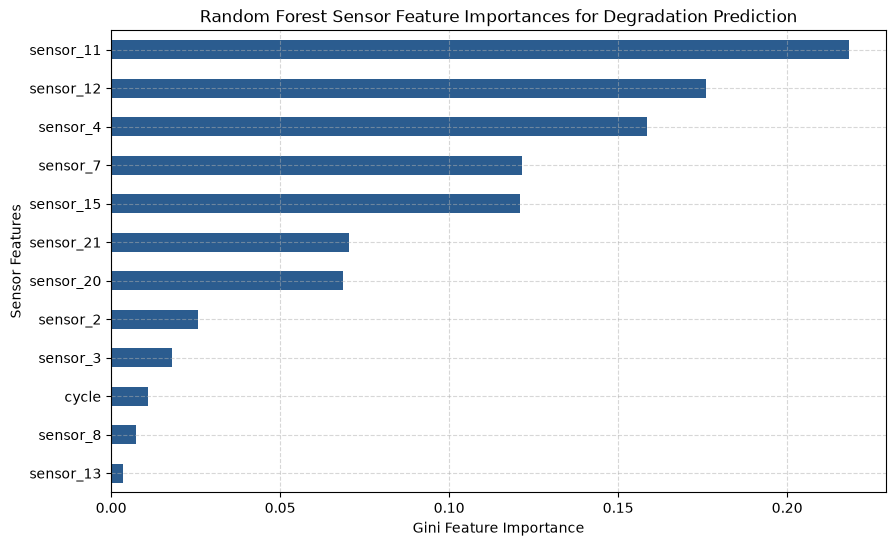

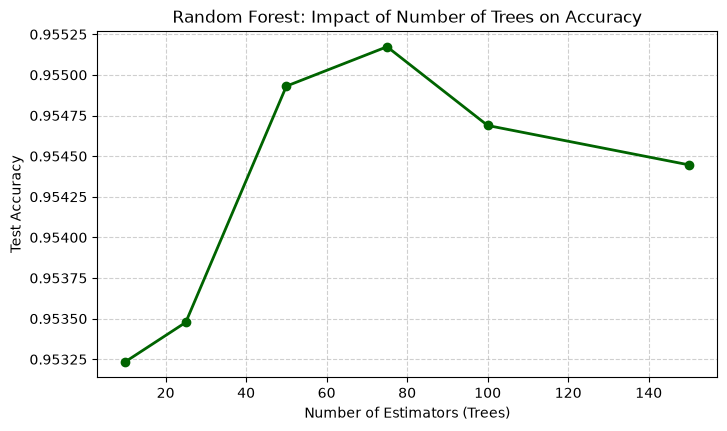

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report


# Load dataset
cols = ["engine_id", "cycle", "setting_1", "setting_2", "setting_3"] + [f"sensor_{i}" for i in range(1, 22)]
df = pd.read_csv("../dataset/CMAPSSData/train_FD001.txt", sep=r"\s+", header=None, names=cols)

df["RUL"] = df.groupby("engine_id")["cycle"].transform("max") - df["cycle"]
df["failure_soon"] = (df["RUL"] <= 30).astype(int)

features = ["cycle", "sensor_2", "sensor_3", "sensor_4", "sensor_7", "sensor_8", "sensor_11", "sensor_12", "sensor_13", "sensor_15", "sensor_20", "sensor_21"]
X = df[features]
y = df["failure_soon"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 1. Train Decision Tree vs Random Forest
dt = DecisionTreeClassifier(max_depth=6, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

rf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# Compare Performance
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Decision Tree": [
        accuracy_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_dt)
    ],
    "Random Forest": [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf)
    ]
})

print("\nModel Comparison (Decision Tree vs Random Forest):")
print(comparison.to_string(index=False))

# 2. Feature Importance Analysis from Random Forest
importances = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importances.plot(kind="barh", color="#2b5c8f")
plt.xlabel("Gini Feature Importance")
plt.ylabel("Sensor Features")
plt.title("Random Forest Sensor Feature Importances for Degradation Prediction")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# 3. Effect of number of estimators in Random Forest
n_estimators_list = [10, 25, 50, 75, 100, 150]
rf_accuracies = []

for n in n_estimators_list:
    clf = RandomForestClassifier(n_estimators=n, max_depth=6, random_state=42)
    clf.fit(X_train, y_train)
    rf_accuracies.append(accuracy_score(y_test, clf.predict(X_test)))

plt.figure(figsize=(8, 4.5))
plt.plot(n_estimators_list, rf_accuracies, marker="o", color="darkgreen", linewidth=2)
plt.xlabel("Number of Estimators (Trees)")
plt.ylabel("Test Accuracy")
plt.title("Random Forest: Impact of Number of Trees on Accuracy")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

print("Experiment 7 Completed Successfully")